In [1]:
!pip install -q landingai-ade pillow pydantic

In [5]:
from landingai_ade import LandingAIADE
from getpass import getpass

API_KEY = getpass("Enter your Landing AI API Key: ")

client = LandingAIADE(apikey=API_KEY)

print("Landing AI client initialized successfully!")

Enter your Landing AI API Key: ··········
Landing AI client initialized successfully!


Saving WhatsApp Image 2026-11-04 at 20.47.34.jpeg to WhatsApp Image 2026-11-04 at 20.47.34 (3).jpeg


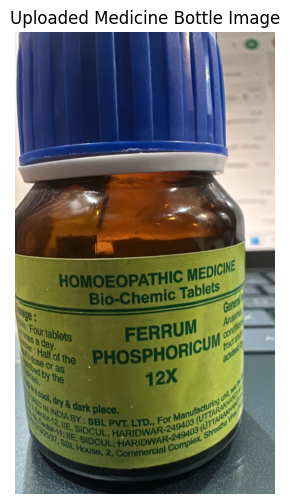

Image uploaded successfully!
Filename: WhatsApp Image 2026-11-04 at 20.47.34 (3).jpeg


In [6]:
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt
import io

# Upload medicine bottle image
uploaded = files.upload()

# Get uploaded filename
filename = next(iter(uploaded))

# Open image
image = Image.open(io.BytesIO(uploaded[filename]))

# Display image
plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Uploaded Medicine Bottle Image")
plt.show()

print("Image uploaded successfully!")
print("Filename:", filename)

In [7]:
from pathlib import Path

# Read medicine bottle label using Landing AI
try:
    result = client.parse(
        document=Path(filename)
    )

    extracted_text = result.markdown

    print("MEDICINE BOTTLE LABEL - EXTRACTED TEXT")
    print("=" * 50)
    print(extracted_text)

except Exception as e:
    print("Error while reading medicine label:")
    print(type(e).__name__, str(e))

MEDICINE BOTTLE LABEL - EXTRACTED TEXT
<a id='0c1d98d4-15e1-4ff1-bc2b-bcfb105de5a9'></a>

HOMOEOPATHIC MEDICINE
Bio-Chemic Tablets
General

<a id='1686524c-3f6f-4021-9425-8ff9814aac45'></a>

Dosage :

Adults : Four tablets 3-4 times a day.

Children : Half of the adult's dose or as prescribed by the physician.

Keep in a cool, dry & dark

MANUFACTURED IN INDIA BY
Plot No. 3, Sector 1, IIE, SIDCUL, Pantnagar - 263 153 (Uttarakhand)

<a id='116ddfe4-0cc0-43f2-8f5f-abb8600c6366'></a>

FERRUM
PHOSPHORICUM
12X

<a id='13cd13c1-5cc2-4f5a-a3d8-d3e63458894f'></a>

<::logo: Unknown
General In
Anaemia
conditions
tract and
advised
The text is printed in dark green on a light yellow background, appearing to be part of a product label.::>

<a id='76f18c1a-7484-4b9f-87cb-5feadebed6d4'></a>

in a cool, dry & dark place.

MANUFACTURED IN INDIA BY: SBL PVT. LTD., For Manufacturing unit, see
Plot No. 3, Sector-12, IIE, SIDCUL, HARIDWAR-249403 (UTTARAKHAND)
Plot No. 42, Sector-11, IIE, SIDCUL, HARIDWAR-2

In [8]:
import re

# Remove HTML tags
cleaned_text = re.sub(r"<[^>]+>", "", extracted_text)

# Remove excessive blank lines
cleaned_text = re.sub(r"\n\s*\n+", "\n", cleaned_text)

# Remove leading and trailing spaces
cleaned_text = cleaned_text.strip()

print("CLEANED MEDICINE LABEL")
print("=" * 50)
print(cleaned_text)

CLEANED MEDICINE LABEL
HOMOEOPATHIC MEDICINE
Bio-Chemic Tablets
General
Dosage :
Adults : Four tablets 3-4 times a day.
Children : Half of the adult's dose or as prescribed by the physician.
Keep in a cool, dry & dark
MANUFACTURED IN INDIA BY
Plot No. 3, Sector 1, IIE, SIDCUL, Pantnagar - 263 153 (Uttarakhand)
FERRUM
PHOSPHORICUM
12X
in a cool, dry & dark place.
MANUFACTURED IN INDIA BY: SBL PVT. LTD., For Manufacturing unit, see
Plot No. 3, Sector-12, IIE, SIDCUL, HARIDWAR-249403 (UTTARAKHAND)
Plot No. 42, Sector-11, IIE, SIDCUL, HARIDWAR-249403 (UTTARAKHAND)
M-1731019/25/37, SBL House, 2, Commercial Complex, Shrestha Vihar,


In [9]:
import re
import json

def extract_medicine_details(text):
    details = {
        "Medicine Name": "Not found",
        "Medicine Type": "Not found",
        "Strength": "Not found",
        "Batch Number": "Not found",
        "Manufacturing Date": "Not found",
        "Expiry Date": "Not found",
        "Manufacturer": "Not found"
    }

    # Identify medicine type
    if re.search(r"hom[o]?eopathic", text, re.I):
        details["Medicine Type"] = "Homeopathic"
    elif re.search(r"ayurvedic", text, re.I):
        details["Medicine Type"] = "Ayurvedic"
    elif re.search(r"allopathic", text, re.I):
        details["Medicine Type"] = "Allopathic"

    # Medicine name (look for common label keywords)
    name_match = re.search(
        r"(?:Medicine Name|Product Name|Brand Name)\s*[:\-]\s*(.+)",
        text, re.I
    )
    if name_match:
        details["Medicine Name"] = name_match.group(1).strip()

    # Strength
    strength_match = re.search(
        r"\b\d+(?:\.\d+)?\s*(?:mg|mcg|g|ml|IU)\b",
        text, re.I
    )
    if strength_match:
        details["Strength"] = strength_match.group()

    # Batch number
    batch_match = re.search(
        r"(?:Batch No\.?|Batch Number|B\.?\s*No\.?)\s*[:\-]?\s*([A-Z0-9/-]+)",
        text, re.I
    )
    if batch_match:
        details["Batch Number"] = batch_match.group(1)

    # Manufacturing date
    mfg_match = re.search(
        r"(?:MFG|MFD|Manufacturing Date)\s*[:\-]?\s*(\d{1,2}[/-]\d{2,4})",
        text, re.I
    )
    if mfg_match:
        details["Manufacturing Date"] = mfg_match.group(1)

    # Expiry date
    exp_match = re.search(
        r"(?:EXP|Expiry|Expiry Date|Use Before)\s*[:\-]?\s*(\d{1,2}[/-]\d{2,4})",
        text, re.I
    )
    if exp_match:
        details["Expiry Date"] = exp_match.group(1)

    # Manufacturer
    manufacturer_match = re.search(
        r"(?:Manufactured by|Mfg\.? by)\s*[:\-]?\s*([^\n]+)",
        text, re.I
    )
    if manufacturer_match:
        details["Manufacturer"] = manufacturer_match.group(1).strip()

    return details


medicine_details = extract_medicine_details(cleaned_text)

print("STRUCTURED MEDICINE INFORMATION")
print("=" * 50)
print(json.dumps(medicine_details, indent=4))

STRUCTURED MEDICINE INFORMATION
{
    "Medicine Name": "Not found",
    "Medicine Type": "Homeopathic",
    "Strength": "Not found",
    "Batch Number": "Not found",
    "Manufacturing Date": "Not found",
    "Expiry Date": "Not found",
    "Manufacturer": "Not found"
}


In [10]:
from pydantic import BaseModel, Field
from typing import Optional

# Define the information to extract
class MedicineLabel(BaseModel):
    medicine_name: Optional[str] = Field(
        default=None,
        description="Exact medicine or product name printed on the label"
    )

    medicine_type: Optional[str] = Field(
        default=None,
        description="Type of medicine explicitly stated on the label"
    )

    strength: Optional[str] = Field(
        default=None,
        description="Medicine strength or concentration with units"
    )

    batch_number: Optional[str] = Field(
        default=None,
        description="Batch or lot number"
    )

    manufacturing_date: Optional[str] = Field(
        default=None,
        description="Manufacturing date exactly as printed"
    )

    expiry_date: Optional[str] = Field(
        default=None,
        description="Expiry date exactly as printed"
    )

    manufacturer: Optional[str] = Field(
        default=None,
        description="Manufacturer name"
    )

    storage_instructions: Optional[str] = Field(
        default=None,
        description="Storage instructions printed on the label"
    )

    warnings: Optional[str] = Field(
        default=None,
        description="Warnings explicitly printed on the label"
    )


print("Medicine extraction schema created successfully!")
print(MedicineLabel.model_json_schema())

Medicine extraction schema created successfully!
{'properties': {'medicine_name': {'anyOf': [{'type': 'string'}, {'type': 'null'}], 'default': None, 'description': 'Exact medicine or product name printed on the label', 'title': 'Medicine Name'}, 'medicine_type': {'anyOf': [{'type': 'string'}, {'type': 'null'}], 'default': None, 'description': 'Type of medicine explicitly stated on the label', 'title': 'Medicine Type'}, 'strength': {'anyOf': [{'type': 'string'}, {'type': 'null'}], 'default': None, 'description': 'Medicine strength or concentration with units', 'title': 'Strength'}, 'batch_number': {'anyOf': [{'type': 'string'}, {'type': 'null'}], 'default': None, 'description': 'Batch or lot number', 'title': 'Batch Number'}, 'manufacturing_date': {'anyOf': [{'type': 'string'}, {'type': 'null'}], 'default': None, 'description': 'Manufacturing date exactly as printed', 'title': 'Manufacturing Date'}, 'expiry_date': {'anyOf': [{'type': 'string'}, {'type': 'null'}], 'default': None, 'descr

In [12]:
import json

try:
    extraction_result = client.v2.extract(
        markdown=extracted_text,
        schema=MedicineLabel.model_json_schema()
    )

    print("AI-EXTRACTED MEDICINE INFORMATION")
    print("=" * 50)
    print(extraction_result)

except Exception as e:
    print("Error:", type(e).__name__)
    print(str(e))

AI-EXTRACTED MEDICINE INFORMATION
V2ExtractResult(extraction={'batch_number': None, 'expiry_date': None, 'manufacturer': 'SBL PVT. LTD.', 'manufacturing_date': None, 'medicine_name': 'FERRUM PHOSPHORICUM', 'medicine_type': 'Bio-Chemic Tablets', 'storage_instructions': 'Keep in a cool, dry & dark place.', 'strength': '12X', 'warnings': None}, extraction_metadata={'batch_number': {'ranges': None, 'value': None}, 'expiry_date': {'ranges': None, 'value': None}, 'manufacturer': {'ranges': [{'end': 847, 'start': 779}], 'value': 'SBL PVT. LTD.'}, 'manufacturing_date': {'ranges': None, 'value': None}, 'medicine_name': {'ranges': [{'end': 454, 'start': 448}, {'end': 467, 'start': 455}], 'value': 'FERRUM PHOSPHORICUM'}, 'medicine_type': {'ranges': [{'end': 91, 'start': 73}], 'value': 'Bio-Chemic Tablets'}, 'storage_instructions': {'ranges': [{'end': 300, 'start': 274}, {'end': 777, 'start': 749}], 'value': 'Keep in a cool, dry & dark place.'}, 'strength': {'ranges': [{'end': 471, 'start': 468}],

In [13]:
import pandas as pd
from IPython.display import display

# Get structured extraction dictionary
medicine_data = extraction_result.extraction

# Convert into readable table
report = pd.DataFrame({
    "Field": [
        key.replace("_", " ").title()
        for key in medicine_data.keys()
    ],
    "Extracted Information": [
        value if value is not None else "Not detected"
        for value in medicine_data.values()
    ]
})

print("MEDICINE LABEL COGNITIVE ASSISTANT")
print("=" * 50)

display(report)

print("\nAnalysis completed successfully!")

MEDICINE LABEL COGNITIVE ASSISTANT


,Field,Extracted Information
0,Batch Number,Not detected
1,Expiry Date,Not detected
2,Manufacturer,SBL PVT. LTD.
3,Manufacturing Date,Not detected
4,Medicine Name,FERRUM PHOSPHORICUM
5,Medicine Type,Bio-Chemic Tablets
6,Storage Instructions,"Keep in a cool, dry & dark place."
7,Strength,12X
8,Warnings,Not detected



Analysis completed successfully!


In [14]:
!pip install -q gradio

In [15]:
import pandas as pd
from pathlib import Path

def analyze_medicine(image_path):

    if image_path is None:
        return "Please upload a medicine bottle image."

    try:
        # Step 1: Read label using Landing AI
        parsed_result = client.v2.parse(
            document=Path(image_path)
        )

        # Step 2: Extract structured medicine information
        result = client.v2.extract(
            markdown=parsed_result.markdown,
            schema=MedicineLabel.model_json_schema()
        )

        # Step 3: Get extracted details
        medicine_data = result.extraction

        # Step 4: Prepare readable output
        report = "## Medicine Label Analysis\n\n"

        for key, value in medicine_data.items():
            field_name = key.replace("_", " ").title()
            field_value = value if value is not None else "Not detected"

            report += f"**{field_name}:** {field_value}\n\n"

        # Step 5: Check whether expiry was detected
        if not medicine_data.get("expiry_date"):
            report += (
                "\n⚠️ **Expiry date could not be verified "
                "from this image.**\n"
            )

        report += (
            "\n---\n"
            "*This tool reads medicine labels. "
            "It does not provide medical advice or verify "
            "whether a medicine is safe to use.*"
        )

        return report

    except Exception as e:
        return f"Error processing image: {type(e).__name__}: {e}"


print("Medicine analysis function created successfully!")

Medicine analysis function created successfully!


In [19]:
import gradio as gr

with gr.Blocks(title="Medicine Label Cognitive Assistant") as demo:

    gr.Markdown(
        """
        # 💊 Medicine Label Cognitive Assistant
        ### Powered by Landing AI

        Upload a medicine bottle image to automatically
        extract its name, strength, manufacturer,
        expiry date, and other label information.
        """
    )

    with gr.Row():

        with gr.Column():
            medicine_image = gr.Image(
                label="Upload Medicine Bottle Image",
                type="filepath",
                sources=["upload", "webcam"]
            )

            analyze_button = gr.Button(
                "🔍 Analyze Medicine Label",
                variant="primary"
            )

        with gr.Column():
            output = gr.Markdown(
                label="Extracted Medicine Information",
                value="Upload an image and click Analyze Medicine Label."
            )

    analyze_button.click(
        fn=analyze_medicine,
        inputs=medicine_image,
        outputs=output
    )

    gr.Markdown(
        """
        ---
        **Disclaimer:** This application extracts information
        from medicine labels. Always verify details against
        the original packaging. It does not provide medical advice.
        """
    )

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://af75c9e9139e54c81c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://af75c9e9139e54c81c.gradio.live


In [18]:
import importlib.util

if importlib.util.find_spec("gtts") is not None:
    print("gTTS is already installed!")
else:
    print("gTTS is not installed.")

gTTS is already installed!


In [20]:
from gtts import gTTS
from IPython.display import Audio, display
import tempfile
import os

def medicine_text_to_speech(medicine_data):
    # Prepare text for speech
    speech_text = "Medicine Label Analysis. "

    fields = {
        "medicine_name": "Medicine name",
        "medicine_type": "Medicine type",
        "strength": "Strength",
        "manufacturer": "Manufacturer",
        "storage_instructions": "Storage instructions",
        "expiry_date": "Expiry date"
    }

    for key, label in fields.items():
        value = medicine_data.get(key)

        if value:
            speech_text += f"{label}: {value}. "
        else:
            speech_text += f"{label}: Not detected. "

    # Generate audio
    tts = gTTS(text=speech_text, lang="en")

    with tempfile.NamedTemporaryFile(
        suffix=".mp3", delete=False
    ) as temp_file:
        audio_path = temp_file.name

    tts.save(audio_path)

    return audio_path


# Test using previously extracted medicine details
audio_path = medicine_text_to_speech(
    extraction_result.extraction
)

print("Medicine voice output generated successfully!")

display(Audio(filename=audio_path))

Medicine voice output generated successfully!


In [21]:
import gradio as gr
from pathlib import Path

def analyze_medicine_with_voice(image_path):

    if image_path is None:
        return "Please upload a medicine bottle image.", None

    try:
        # Step 1: Read the label using Landing AI
        parsed_result = client.v2.parse(
            document=Path(image_path)
        )

        # Step 2: Extract medicine information
        result = client.v2.extract(
            markdown=parsed_result.markdown,
            schema=MedicineLabel.model_json_schema()
        )

        medicine_data = result.extraction

        # Step 3: Generate formatted report
        report = "## Medicine Label Analysis\n\n"

        for key, value in medicine_data.items():
            field_name = key.replace("_", " ").title()
            field_value = value if value is not None else "Not detected"

            report += f"**{field_name}:** {field_value}\n\n"

        if not medicine_data.get("expiry_date"):
            report += (
                "⚠️ **Expiry date could not be verified "
                "from this image.**\n\n"
            )

        report += (
            "---\n"
            "*Always verify extracted information against "
            "the original medicine label.*"
        )

        # Step 4: Generate voice output
        audio_path = medicine_text_to_speech(medicine_data)

        return report, audio_path

    except Exception as e:
        return f"Error: {type(e).__name__}: {e}", None


# Create updated Gradio interface
with gr.Blocks(
    title="Medicine Label Cognitive Assistant"
) as demo_voice:

    gr.Markdown(
        """
        # 💊 Medicine Label Cognitive Assistant
        ### Powered by Landing AI

        Upload a medicine bottle image to read its label,
        extract important information, and listen to the results.
        """
    )

    with gr.Row():

        with gr.Column():

            medicine_image = gr.Image(
                label="Upload Medicine Bottle Image",
                type="filepath",
                sources=["upload", "webcam"]
            )

            analyze_button = gr.Button(
                "🔍 Analyze Medicine Label",
                variant="primary"
            )

        with gr.Column():

            output = gr.Markdown(
                value="Upload an image to begin."
            )

            audio_output = gr.Audio(
                label="🔊 Listen to Medicine Information",
                type="filepath",
                interactive=False
            )

    analyze_button.click(
        fn=analyze_medicine_with_voice,
        inputs=medicine_image,
        outputs=[output, audio_output]
    )

    gr.Markdown(
        """
        ---
        **Disclaimer:** This assistant reads medicine labels.
        It does not provide medical advice or verify medication safety.
        """
    )


demo_voice.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://aa35cf5a09498d8fa0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [22]:
def answer_medicine_question(question, medicine_data):

    if not question or not question.strip():
        return "Please enter a question."

    if not medicine_data:
        return "Please analyze a medicine label first."

    question = question.lower().strip()

    # Identify the requested information
    question_fields = [
        (["expiry", "expire", "expiration", "valid until"],
         "expiry_date", "Expiry date"),

        (["manufacturing date", "mfg date", "manufactured when"],
         "manufacturing_date", "Manufacturing date"),

        (["batch", "lot number"],
         "batch_number", "Batch number"),

        (["storage", "store", "keep"],
         "storage_instructions", "Storage instructions"),

        (["warning", "precaution", "caution"],
         "warnings", "Warnings"),

        (["strength", "potency", "concentration"],
         "strength", "Strength"),

        (["manufacturer", "manufactured by", "company", "made by"],
         "manufacturer", "Manufacturer"),

        (["type", "category", "kind"],
         "medicine_type", "Medicine type"),

        (["name", "called", "which medicine", "what medicine"],
         "medicine_name", "Medicine name")
    ]

    for keywords, field, label in question_fields:
        if any(keyword in question for keyword in keywords):

            value = medicine_data.get(field)

            if value:
                return f"**{label}:** {value}"

            return (
                f"**{label}:** Not detected on the uploaded label. "
                "Please check the original packaging."
            )

    return (
        "I can answer questions about the medicine name, "
        "strength, manufacturer, batch number, manufacturing "
        "date, expiry date, storage instructions, and warnings. "
        "Please ask about one of these details."
    )


# Test using the previously extracted label
test_question = "What is the strength of this medicine?"

answer = answer_medicine_question(
    test_question,
    extraction_result.extraction
)

print("Question:", test_question)
print("Answer:", answer)

Question: What is the strength of this medicine?
Answer: **Strength:** 12X


In [23]:
import gradio as gr
from pathlib import Path

# Analyze medicine and save extracted information
def analyze_and_save(image_path):

    if image_path is None:
        return "Please upload an image.", None, {}

    try:
        # Read medicine label
        parsed = client.v2.parse(
            document=Path(image_path)
        )

        # Extract medicine details
        result = client.v2.extract(
            markdown=parsed.markdown,
            schema=MedicineLabel.model_json_schema()
        )

        medicine_data = result.extraction

        # Prepare report
        report = "## Medicine Label Analysis\n\n"

        for key, value in medicine_data.items():
            field = key.replace("_", " ").title()
            value = value if value is not None else "Not detected"
            report += f"**{field}:** {value}\n\n"

        if not medicine_data.get("expiry_date"):
            report += (
                "⚠️ **Expiry date could not be verified.**\n\n"
            )

        report += (
            "---\n"
            "*Always verify information against the original label.*"
        )

        # Generate voice output
        try:
            audio_path = medicine_text_to_speech(medicine_data)
        except Exception:
            audio_path = None
            report += "\n\nAudio could not be generated."

        return report, audio_path, medicine_data

    except Exception as e:
        return f"Error: {type(e).__name__}: {e}", None, {}


# Question-answering function
def ask_question(question, medicine_data):

    return answer_medicine_question(
        question,
        medicine_data
    )


# Create complete Gradio interface
with gr.Blocks(
    title="Medicine Label Cognitive Assistant"
) as final_demo:

    gr.Markdown(
        """
        # 💊 Medicine Label Cognitive Assistant
        ### Powered by Landing AI

        Upload a medicine bottle image to read its label,
        extract important details, listen to the information,
        and ask questions.
        """
    )

    # Store extracted medicine details
    medicine_state = gr.State({})

    with gr.Row():

        with gr.Column():

            image_input = gr.Image(
                label="Upload Medicine Bottle Image",
                type="filepath",
                sources=["upload", "webcam"]
            )

            analyze_btn = gr.Button(
                "🔍 Analyze Medicine Label",
                variant="primary"
            )

            audio_output = gr.Audio(
                label="🔊 Listen to Medicine Information",
                type="filepath",
                interactive=False
            )

        with gr.Column():

            medicine_output = gr.Markdown(
                value="Upload an image to begin."
            )

    gr.Markdown("## 💬 Ask Questions About the Medicine")

    question_input = gr.Textbox(
        label="Your Question",
        placeholder="Example: What is the strength of this medicine?"
    )

    ask_btn = gr.Button(
        "Ask Assistant",
        variant="primary"
    )

    answer_output = gr.Markdown(
        value="Your answer will appear here."
    )

    # Analyze uploaded image
    analyze_btn.click(
        fn=analyze_and_save,
        inputs=image_input,
        outputs=[
            medicine_output,
            audio_output,
            medicine_state
        ]
    )

    # Answer questions using extracted details
    ask_btn.click(
        fn=ask_question,
        inputs=[
            question_input,
            medicine_state
        ],
        outputs=answer_output
    )

    gr.Markdown(
        """
        ---
        **Disclaimer:** This application reads medicine labels
        and answers questions about printed information.
        It does not provide medical advice, prescribe medication,
        or determine whether a medicine is safe to use.
        """
    )


final_demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9eb46388fb66865356.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

# ============================================================
# UCS420 COGNITIVE COMPUTING - LAB ASSIGNMENT 9
# Q2: EMOTION-AWARE COGNITIVE ASSISTANT
# Facial Expression Detection using DeepFace + Gradio
# ============================================================

# STEP 1: INSTALL LIBRARIES
import sys
import subprocess

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "deepface", "tf-keras", "gradio",
    "opencv-python-headless", "matplotlib", "pillow"
])

# STEP 2: IMPORT LIBRARIES
import cv2
import numpy as np
import matplotlib.pyplot as plt
import gradio as gr
from deepface import DeepFace
from PIL import Image
import tempfile
import os

print("All libraries imported successfully!")

# STEP 3: DEFINE ASSISTANT RESPONSES
responses = {
    "happy": (
        "Your facial expression looks happy! "
        "It's nice to see a smile."
    ),
    "sad": (
        "Your expression appears sad. "
        "If you're having a difficult day, "
        "consider taking a break or talking to someone."
    ),
    "angry": (
        "Your expression appears angry. "
        "Taking a short break might help you relax."
    ),
    "surprise": (
        "You look surprised! "
        "Something seems to have caught your attention."
    ),
    "fear": (
        "Your expression resembles fear. "
        "If you're feeling uneasy, consider taking a moment "
        "to get comfortable."
    ),
    "disgust": (
        "Your expression resembles disgust. "
        "Would you like to take a short break?"
    ),
    "neutral": (
        "Your expression looks neutral. "
        "Hope you're having a good day!"
    )
}

# STEP 4: DEFINE EMOTION DETECTION FUNCTION
def detect_emotion(image):

    if image is None:
        return (
            "Please upload an image.",
            None,
            None
        )

    try:
        # Convert image to RGB numpy array
        img = np.array(image.convert("RGB"))

        # Convert RGB to BGR for OpenCV/DeepFace
        img_bgr = cv2.cvtColor(
            img, cv2.COLOR_RGB2BGR
        )

        # Analyze facial expressions
        analysis = DeepFace.analyze(
            img_path=img_bgr,
            actions=["emotion"],
            detector_backend="opencv",
            enforce_detection=True,
            silent=True
        )

        # DeepFace returns a list of detected faces
        if not analysis:
            return (
                "No face detected.",
                image,
                None
            )

        # Select the largest detected face
        result = max(
            analysis,
            key=lambda face: (
                face["region"]["w"] *
                face["region"]["h"]
            )
        )

        emotion = result["dominant_emotion"]
        scores = result["emotion"]
        confidence = float(scores[emotion])

        # STEP 5: DRAW FACE BOUNDING BOX
        region = result["region"]

        x = int(region["x"])
        y = int(region["y"])
        w = int(region["w"])
        h = int(region["h"])

        annotated = img.copy()

        cv2.rectangle(
            annotated,
            (x, y),
            (x + w, y + h),
            (0, 200, 100),
            3
        )

        cv2.putText(
            annotated,
            f"{emotion.upper()} {confidence:.1f}%",
            (max(0, x), max(25, y - 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 180, 100),
            2
        )

        # STEP 6: GENERATE EMOTION CHART
        labels = list(scores.keys())
        values = [float(scores[k]) for k in labels]

        fig, ax = plt.subplots(figsize=(8, 4))

        bars = ax.barh(labels, values)

        ax.set_xlim(0, 100)
        ax.set_xlabel("Model Score (%)")
        ax.set_title("Facial Expression Analysis")

        for bar, value in zip(bars, values):
            ax.text(
                value + 1,
                bar.get_y() + bar.get_height() / 2,
                f"{value:.1f}%",
                va="center",
                fontsize=9
            )

        ax.set_xlim(0, 115)
        plt.tight_layout()

        # STEP 7: GENERATE COGNITIVE RESPONSE
        assistant_response = responses.get(
            emotion,
            "Facial expression analyzed."
        )

        report = f"""
## Facial Expression Analysis

**Detected Expression:** {emotion.title()}

**Model Score:** {confidence:.2f}%

**Faces Detected:** {len(analysis)}

### Cognitive Assistant Response

{assistant_response}

---

*The detected expression is an AI estimate,
not proof of a person's actual emotional state.*
"""

        return report, Image.fromarray(annotated), fig

    except ValueError:
        return (
            "No clear face detected. Please upload "
            "a well-lit image with a visible face.",
            image,
            None
        )

    except Exception as e:
        return (
            f"Analysis failed: {type(e).__name__}: {str(e)}",
            image,
            None
        )


# STEP 8: CREATE GRADIO INTERFACE
with gr.Blocks(
    title="Emotion-Aware Cognitive Assistant"
) as demo:

    gr.Markdown("""
# Emotion-Aware Cognitive Assistant

### Facial Expression Detection using DeepFace

Upload a face image or capture one using your webcam.

The assistant detects facial expressions, estimates
expression scores, and provides a friendly response.
""")

    with gr.Row():

        with gr.Column():

            input_image = gr.Image(
                label="Upload or Capture Face Image",
                type="pil",
                sources=["upload", "webcam"]
            )

            analyze_button = gr.Button(
                "Analyze Facial Expression",
                variant="primary"
            )

        with gr.Column():

            output_image = gr.Image(
                label="Detected Face"
            )

            output_text = gr.Markdown(
                value="Upload an image to begin."
            )

    emotion_chart = gr.Plot(
        label="Facial Expression Scores"
    )

    analyze_button.click(
        fn=detect_emotion,
        inputs=input_image,
        outputs=[
            output_text,
            output_image,
            emotion_chart
        ]
    )

    gr.Markdown("""
---
**Note:** Facial expressions do not always reflect
a person's actual emotions. This application is
for educational demonstration only.
""")

# STEP 9: LAUNCH APPLICATION
print("Launching Emotion-Aware Cognitive Assistant...")
demo.launch(share=True, debug=True)


26-11-04 16:45:00 - Directory /root/.deepface has been created
26-11-04 16:45:00 - Directory /root/.deepface/weights has been created
All libraries imported successfully!
Launching Emotion-Aware Cognitive Assistant...
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://ea16088f7c1151a1e1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


26-11-04 16:46:54 - 🔗 facial_expression_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5 to /root/.deepface/weights/facial_expression_model_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5
To: /root/.deepface/weights/facial_expression_model_weights.h5
100%|██████████| 5.98M/5.98M [00:00<00:00, 70.6MB/s]
